# Probability

In [1]:
from itertools import combinations, permutations, product
from math import comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Challenge 1
There is a box with 10 white balls, 12 red balls and 8 black balls. Calculate the probability of:
* Taking a white ball out.
* Taking a white ball on first extraction and a black ball out on second extraction without replacing the first one.
* Taking a white ball on first extraction and a black ball out on second extraction replacing the first one.
* Taking 3 balls and them being all different colours.

### Solution

There are 10 + 12 + 8 = 30 balls in the box. The sample space is finite and every ball is equally likely to be picked, so Laplace's rule can be used:

$$P(A) = \frac{|A|}{|S|}$$

**A white ball:** 10 of the 30 balls are white.

$$P(W) = \frac{10}{30} = \frac{1}{3} \approx 0.333$$

**White, then black, without replacement:** the white ball stays out, so the first extraction changes the second one. These are dependent events and we need $P(A \cap B) = P(A) \cdot P(B|A)$. There are only 29 balls left, but all 8 black balls are still in the box.

$$P(W_1 \cap B_2) = P(W_1) \cdot P(B_2|W_1) = \frac{10}{30} \cdot \frac{8}{29} = \frac{8}{87} \approx 0.092$$

**White, then black, with replacement:** now the white ball goes back in the box, so the first extraction says nothing about the second one. The events are independent and the probabilities can just be multiplied.

$$P(W_1 \cap B_2) = P(W_1) \cdot P(B_2) = \frac{10}{30} \cdot \frac{8}{30} = \frac{4}{45} \approx 0.089$$

This is slightly less than without replacement. That makes sense, since a white ball that stays out makes black a bit likelier on the second try.

**3 balls, all different colours:** the challenge does not mention replacing here, so I assume that the 3 balls stay out and the order doesn't matter. There are $\binom{30}{3} = 4060$ possible groups of 3 balls. All different colours means one ball of each colour, so 10 * 12 * 8 = 960 of those groups count.

$$P(\text{all different}) = \frac{10 \cdot 12 \cdot 8}{\binom{30}{3}} = \frac{960}{4060} = \frac{48}{203} \approx 0.236$$

So it happens in roughly **24%** of the cases.

Verifying all of this by counting the outcomes one by one instead of using the formulas:

In [2]:
balls = ["white"] * 10 + ["red"] * 12 + ["black"] * 8

# all the possible outcomes of each experiment
no_replacement = list(permutations(balls, 2))
with_replacement = list(product(balls, repeat=2))
three_balls = list(combinations(balls, 3))

pd.DataFrame(
    {
        "counted": [
            balls.count("white") / len(balls),
            no_replacement.count(("white", "black")) / len(no_replacement),
            with_replacement.count(("white", "black")) / len(with_replacement),
            sum(len(set(group)) == 3 for group in three_balls) / len(three_balls),
        ],
        "formula": [
            10 / 30,
            10 / 30 * 8 / 29,
            10 / 30 * 8 / 30,
            10 * 12 * 8 / comb(30, 3),
        ],
    },
    index=["white", "white, black (no replacement)", "white, black (replacement)", "3 different colours"],
).round(4)

,counted,formula
white,0.3333,0.3333
"white, black (no replacement)",0.0920,0.0920
"white, black (replacement)",0.0889,0.0889
3 different colours,0.2365,0.2365


## Challenge 2

You want to go on picnic on Saturday. You hate rain, and would know to plan your weekend. To help you make a decision, you gather the following data about rainy days:

* 40% of all days are cloudy.
* About 50% of cloudy days are rainy. 
* About 20% of non-cloudy days are rainy.

What is the chance of rain during next Saturday?

### Solution

Every day is either cloudy or not, so these two cases split up all the days without any overlap. It can rain in both of them, so this is a case for the law of total probability. With $C$ = cloudy and $R$ = rainy we know:

- $P(C) = 0.4$, so $P(\overline{C}) = 0.6$
- $P(R|C) = 0.5$
- $P(R|\overline{C}) = 0.2$

$$P(R) = P(R|C) \cdot P(C) + P(R|\overline{C}) \cdot P(\overline{C})$$

$$P(R) = 0.5 \cdot 0.4 + 0.2 \cdot 0.6 = 0.2 + 0.12 = 0.32$$

So there is a ~**32%** chance of rain next Saturday and a ~68% chance that the picnic stays dry. The data says nothing about Saturdays in particular, so Saturday is treated like any other day here.

Verifying this with a Monte Carlo simulation of a million days:

In [3]:
rng = np.random.default_rng(42)
n_days = 1_000_000

# first decide if the day is cloudy, then if it rains on that kind of day
cloudy = rng.random(n_days) < 0.4
rainy = rng.random(n_days) < np.where(cloudy, 0.5, 0.2)

print(f"calculated: {0.5 * 0.4 + 0.2 * 0.6:.4f}")
print(f"simulated:  {rainy.mean():.4f}")

calculated: 0.3200
simulated:  0.3200


## Challenge 3

A and B are events of a probability such that $P(A) = 0.3$, $P(B) = 0.6$ and $P(A \cap B) = 0.1$

Which of the following statements are true?  
**HINT: draw a big Venn Diagram by your side**  
* $P(\overline{A}) = 0.7$
* $P(A \cup B) = 0.6$
* $P(A \cap \overline{B}) = 0.2$
* $P(A \cup \overline{A}) = 1$  
* $P(A \cap (B \cup \overline{B})) = 0.4$
* $P(\overline{A} \cap \overline{B}) = 0.3$
* $P(\overline{A \cap B}) = 0.9$

### Solution

Following the hint, I split the Venn diagram into its 4 regions first, since all of the statements can be read off from those:

| Region | Calculation | Probability |
|:---|:---|:---|
| only A, $A \cap \overline{B}$ | 0.3 - 0.1 | 0.2 |
| both, $A \cap B$ | given | 0.1 |
| only B, $\overline{A} \cap B$ | 0.6 - 0.1 | 0.5 |
| neither, $\overline{A} \cap \overline{B}$ | 1 - (0.2 + 0.1 + 0.5) | 0.2 |

Now to the statements:

1. $P(\overline{A}) = 0.7$ is **true**. It's the complement: $1 - P(A) = 1 - 0.3 = 0.7$.
2. $P(A \cup B) = 0.6$ is **false**. By the inclusion-exclusion principle $P(A) + P(B) - P(A \cap B) = 0.3 + 0.6 - 0.1 = 0.8$.
3. $P(A \cap \overline{B}) = 0.2$ is **true**. That's the "only A" region: $0.3 - 0.1 = 0.2$.
4. $P(A \cup \overline{A}) = 1$ is **true**. A and its complement together are the whole sample space.
5. $P(A \cap (B \cup \overline{B})) = 0.4$ is **false**. $B \cup \overline{B}$ is the whole sample space, so only A is left and the result is $P(A) = 0.3$.
6. $P(\overline{A} \cap \overline{B}) = 0.3$ is **false**. That's the "neither" region: $1 - P(A \cup B) = 1 - 0.8 = 0.2$.
7. $P(\overline{A \cap B}) = 0.9$ is **true**. It's the complement of the intersection: $1 - 0.1 = 0.9$.

So 4 statements are true (1, 3, 4, 7) and 3 are false (2, 5, 6).

Verifying this by calculating every statement from the 4 regions only:

In [4]:
# the four regions of the Venn diagram
both = 0.1
only_a = 0.3 - both
only_b = 0.6 - both
neither = 1 - (only_a + both + only_b)

statements = [
    ("P(not A) = 0.7", only_b + neither, 0.7),
    ("P(A or B) = 0.6", only_a + both + only_b, 0.6),
    ("P(A and not B) = 0.2", only_a, 0.2),
    ("P(A or not A) = 1", only_a + both + only_b + neither, 1),
    ("P(A and (B or not B)) = 0.4", only_a + both, 0.4),
    ("P(not A and not B) = 0.3", neither, 0.3),
    ("P(not (A and B)) = 0.9", only_a + only_b + neither, 0.9),
]

result = pd.DataFrame(statements, columns=["statement", "calculated", "claimed"])
# isclose, because 0.3 - 0.1 is not exactly 0.2 for floats
result["true"] = np.isclose(result["calculated"], result["claimed"])
result.round(2)

,statement,calculated,claimed,true
0,P(not A) = 0.7,0.7,0.7,True
1,P(A or B) = 0.6,0.8,0.6,False
2,P(A and not B) = 0.2,0.2,0.2,True
3,P(A or not A) = 1,1.0,1.0,True
4,P(A and (B or not B)) = 0.4,0.3,0.4,False
5,P(not A and not B) = 0.3,0.2,0.3,False
6,P(not (A and B)) = 0.9,0.9,0.9,True


## Challenge 4

 * If someone flies to China, the probability of getting Covid is 1%  
 * If someone flies to Italy, the probability of getting Covid is 20%  

I roll 1 dice with numbers 1, 2, 3, 4, 5, 6:  
 * If 1: I fly to Italy
 * If not 1: I fly to China

During my trip, I got Covid. What is the probability that I flew to China?

### Solution

Here we already know the result (Covid) and are looking for what came before it (the flight to China). So the conditional probability has to be turned around, which is exactly what Bayes' theorem does. With $C$ = flew to China, $I$ = flew to Italy and $V$ = got Covid:

$$P(C|V) = \frac{P(V|C) \cdot P(C)}{P(V)}$$

**Prior:** the dice decides where I fly before anything else happens. Only a 1 leads to Italy.

$$P(I) = \frac{1}{6} \qquad P(C) = \frac{5}{6}$$

**Likelihood:** the chance of getting Covid in each country.

$$P(V|C) = 0.01 \qquad P(V|I) = 0.2$$

**Marginal probability:** the chance of getting Covid at all, with the law of total probability.

$$P(V) = P(V|C) \cdot P(C) + P(V|I) \cdot P(I) = 0.01 \cdot \frac{5}{6} + 0.2 \cdot \frac{1}{6} = \frac{0.25}{6} \approx 0.042$$

**Posterior:** putting it all together.

$$P(C|V) = \frac{0.01 \cdot \frac{5}{6}}{\frac{0.25}{6}} = \frac{0.05}{0.25} = 0.2$$

So the probability that I flew to China is **20%** and the probability for Italy is 80%. That is the interesting part: I fly to China 5 out of 6 times, but once I have Covid, Italy is by far the likelier destination. Going to China is only 5 times likelier, while getting Covid in Italy is 20 times likelier, so Italy wins with a ratio of 4 to 1.

Verifying this by simulating a million trips and only looking at those where I got Covid:

In [5]:
rng = np.random.default_rng(42)
n_trips = 1_000_000

dice = rng.integers(1, 7, size=n_trips)
china = dice != 1
covid = rng.random(n_trips) < np.where(china, 0.01, 0.2)

print(f"calculated: {(0.01 * 5 / 6) / (0.25 / 6):.4f}")
print(f"simulated:  {china[covid].mean():.4f}")

calculated: 0.2000
simulated:  0.1969


## BONUS

You roll 2 dice. What is the probability that the sum of the numbers is 7? And 8? And 9? Then simulate 10000 times and draw a countplot.

Rolling 2 dice gives the Cartesian product of {1, 2, 3, 4, 5, 6} with itself, so there are 6 * 6 = 36 ordered pairs. (1, 6) and (6, 1) count as two different outcomes here. All of the pairs are equally likely, so it's Laplace's rule again and we just have to count the pairs for each sum:

| Sum | Pairs | Probability |
|:---|:---|:---|
| 7 | (1,6) (2,5) (3,4) (4,3) (5,2) (6,1) | $\frac{6}{36} = \frac{1}{6} \approx 0.167$ |
| 8 | (2,6) (3,5) (4,4) (5,3) (6,2) | $\frac{5}{36} \approx 0.139$ |
| 9 | (3,6) (4,5) (5,4) (6,3) | $\frac{4}{36} = \frac{1}{9} \approx 0.111$ |

Simulating 10000 rolls now and comparing them to the exact values, which are also added to the countplot as dots:

,exact,simulated
7,0.1667,0.1645
8,0.1389,0.1351
9,0.1111,0.1109


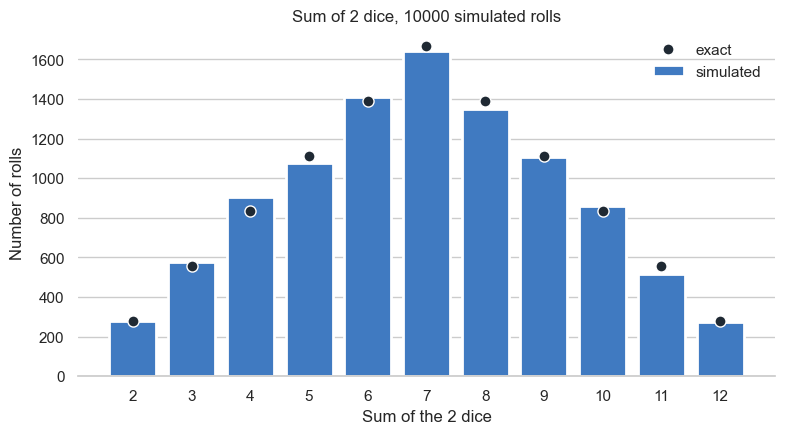

In [6]:
rng = np.random.default_rng(42)
n_rolls = 10_000

sums = rng.integers(1, 7, size=(n_rolls, 2)).sum(axis=1)

# exact probabilities by counting all the 36 pairs
pairs = list(product(range(1, 7), repeat=2))
possible_sums = list(range(2, 13))
exact = pd.Series([sum(a + b == s for a, b in pairs) / len(pairs) for s in possible_sums], index=possible_sums)
simulated = pd.Series(sums).value_counts(normalize=True).reindex(possible_sums)

display(pd.DataFrame({"exact": exact, "simulated": simulated}).loc[[7, 8, 9]].round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.countplot(x=sums, order=possible_sums, color="#2a78d6", edgecolor="white", linewidth=2, label="simulated", ax=ax)
ax.plot(range(len(possible_sums)), exact * n_rolls, "o", markersize=8, color="#1f2933", markeredgecolor="white", label="exact")

ax.set_title("Sum of 2 dice, 10000 simulated rolls")
ax.set_xlabel("Sum of the 2 dice")
ax.set_ylabel("Number of rolls")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
sns.despine(left=True)
plt.show()

As expected the simulation is quite close to the exact values: 7 shows up in ~16.5% of the rolls (exact: 16.7%), 8 in ~13.5% (exact: 13.9%) and 9 in ~11.1% (exact: 11.1%).

The countplot also shows the shape of the whole distribution. It is symmetric around 7, which is the most likely sum since it has the most pairs. The small differences between the bars and the dots are just the randomness of the simulation and should get smaller with more rolls.